**Title:** Predicting Breast Cancer Detection using Machine Learning Algorithm

**Student Name:** Pritom Saha

**Student ID:** 30118440

## Import Libraries

In [23]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import warnings

# remove  warnings
warnings.filterwarnings('ignore')

In [24]:
#load the dataset
b_c_dataset = pd.read_csv('breast-cancer-wisconsin.csv')

- Check first 5 records

In [25]:
b_c_dataset.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


- Check last 5 records

In [26]:
b_c_dataset.tail()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400
568,92751,B,7.76,24.54,47.92,181.0,0.05263,0.04362,0.00000,0.00000,...,9.456,30.37,59.16,268.6,0.08996,0.06444,0.0000,0.0000,0.2871,0.07039


- Check numbera of rows and columns in dataset 

In [27]:
b_c_dataset.shape

(569, 32)

- Insignts 
in our dataset there is 569 rows and 32 columsn 

- CHeck all columns names 

In [28]:
b_c_dataset.columns

Index(['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean',
       'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave_points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave_points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'concavity_worst', 'concave_points_worst',
       'symmetry_worst', 'fractal_dimension_worst'],
      dtype='object')

From result we can see there is one column name ID. we don't need this column for our analyis for this reason remove this column

In [29]:
b_c_dataset = b_c_dataset.drop('id', axis=1)

In [30]:
b_c_dataset.columns

Index(['diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean',
       'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave_points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave_points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'concavity_worst', 'concave_points_worst',
       'symmetry_worst', 'fractal_dimension_worst'],
      dtype='object')

In [31]:
len(b_c_dataset)

569

Understanding the Data

In [32]:
# Check the data types and summary statistics
b_c_dataset.info()



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   diagnosis                569 non-null    object 
 1   radius_mean              569 non-null    float64
 2   texture_mean             569 non-null    float64
 3   perimeter_mean           569 non-null    float64
 4   area_mean                569 non-null    float64
 5   smoothness_mean          569 non-null    float64
 6   compactness_mean         569 non-null    float64
 7   concavity_mean           569 non-null    float64
 8   concave_points_mean      569 non-null    float64
 9   symmetry_mean            569 non-null    float64
 10  fractal_dimension_mean   569 non-null    float64
 11  radius_se                569 non-null    float64
 12  texture_se               569 non-null    float64
 13  perimeter_se             569 non-null    float64
 14  area_se                  5

In [33]:
b_c_dataset.describe()

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


In [34]:
print(b_c_dataset.isnull().sum())

diagnosis                  0
radius_mean                0
texture_mean               0
perimeter_mean             0
area_mean                  0
smoothness_mean            0
compactness_mean           0
concavity_mean             0
concave_points_mean        0
symmetry_mean              0
fractal_dimension_mean     0
radius_se                  0
texture_se                 0
perimeter_se               0
area_se                    0
smoothness_se              0
compactness_se             0
concavity_se               0
concave_points_se          0
symmetry_se                0
fractal_dimension_se       0
radius_worst               0
texture_worst              0
perimeter_worst            0
area_worst                 0
smoothness_worst           0
compactness_worst          0
concavity_worst            0
concave_points_worst       0
symmetry_worst             0
fractal_dimension_worst    0
dtype: int64


In [35]:
b_c_dataset.isnull().sum()

diagnosis                  0
radius_mean                0
texture_mean               0
perimeter_mean             0
area_mean                  0
smoothness_mean            0
compactness_mean           0
concavity_mean             0
concave_points_mean        0
symmetry_mean              0
fractal_dimension_mean     0
radius_se                  0
texture_se                 0
perimeter_se               0
area_se                    0
smoothness_se              0
compactness_se             0
concavity_se               0
concave_points_se          0
symmetry_se                0
fractal_dimension_se       0
radius_worst               0
texture_worst              0
perimeter_worst            0
area_worst                 0
smoothness_worst           0
compactness_worst          0
concavity_worst            0
concave_points_worst       0
symmetry_worst             0
fractal_dimension_worst    0
dtype: int64

In [36]:
# Check the distribution of the target variable
print(b_c_dataset['diagnosis'].value_counts())

diagnosis
B    357
M    212
Name: count, dtype: int64


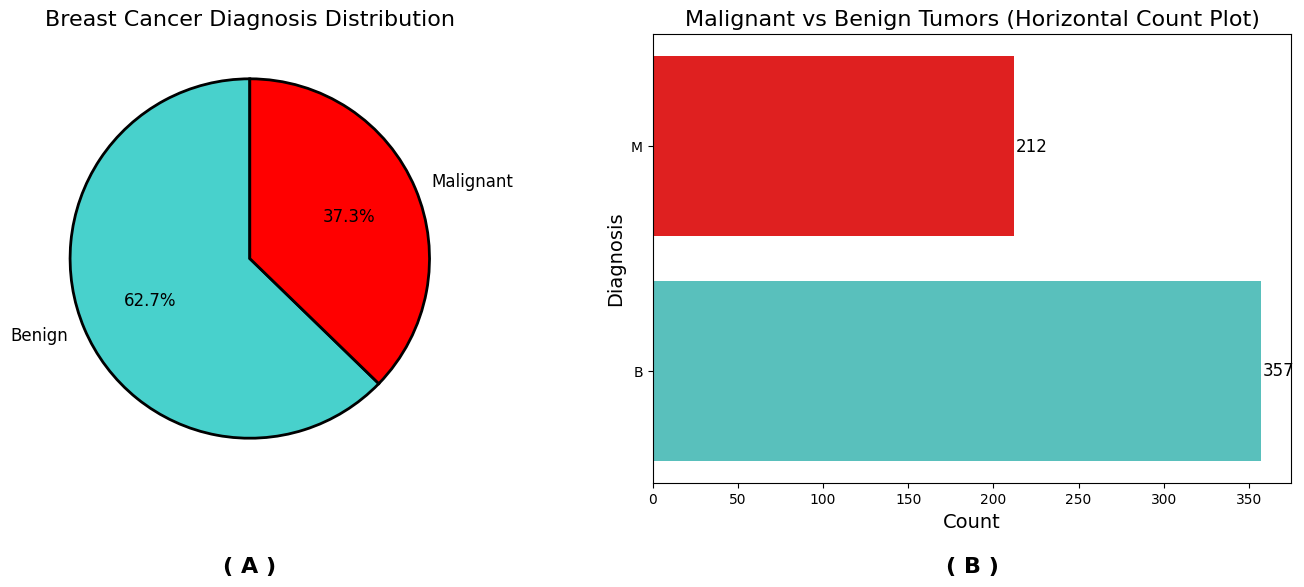

In [37]:
# Assuming you have the dataset `breast_cancer_dataset`
labels = ['Benign', 'Malignant']
values = b_c_dataset['diagnosis'].value_counts()
colors = ['mediumturquoise', 'red']

# Create a figure with 1 row and 2 columns for subplots
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Pie chart
axes[0].pie(values, labels=labels, autopct='%1.1f%%', startangle=90, colors=colors, textprops={'fontsize': 12},
            wedgeprops={'edgecolor': 'black', 'linewidth': 2})
axes[0].set_title('Breast Cancer Diagnosis Distribution', fontsize=16)

# Horizontal count plot
ax = sns.countplot(ax=axes[1], y='diagnosis', data=b_c_dataset, 
                   palette={'B': 'mediumturquoise', 'M': 'red'})  # Use `y` instead of `x` for horizontal orientation
axes[1].set_ylabel('Diagnosis', fontsize=14)
axes[1].set_xlabel('Count', fontsize=14)
axes[1].set_title('Malignant vs Benign Tumors (Horizontal Count Plot)', fontsize=16)

# Add count annotations on the bars
for p in ax.patches:
    count = int(p.get_width())  # Get the width of each bar (count)
    y_position = p.get_y() + p.get_height() / 2  # Center of the bar
    axes[1].text(count + 1, y_position, str(count), va='center', fontsize=12)  # Add text to the right of the bar

# Adjust layout
axes[0].text(0.5, -0.2, "( A )", transform=axes[0].transAxes, fontsize=16, fontweight='bold', ha='center')
axes[1].text(0.5, -0.2, "( B )", transform=axes[1].transAxes, fontsize=16, fontweight='bold', ha='center')

plt.tight_layout()
plt.show()



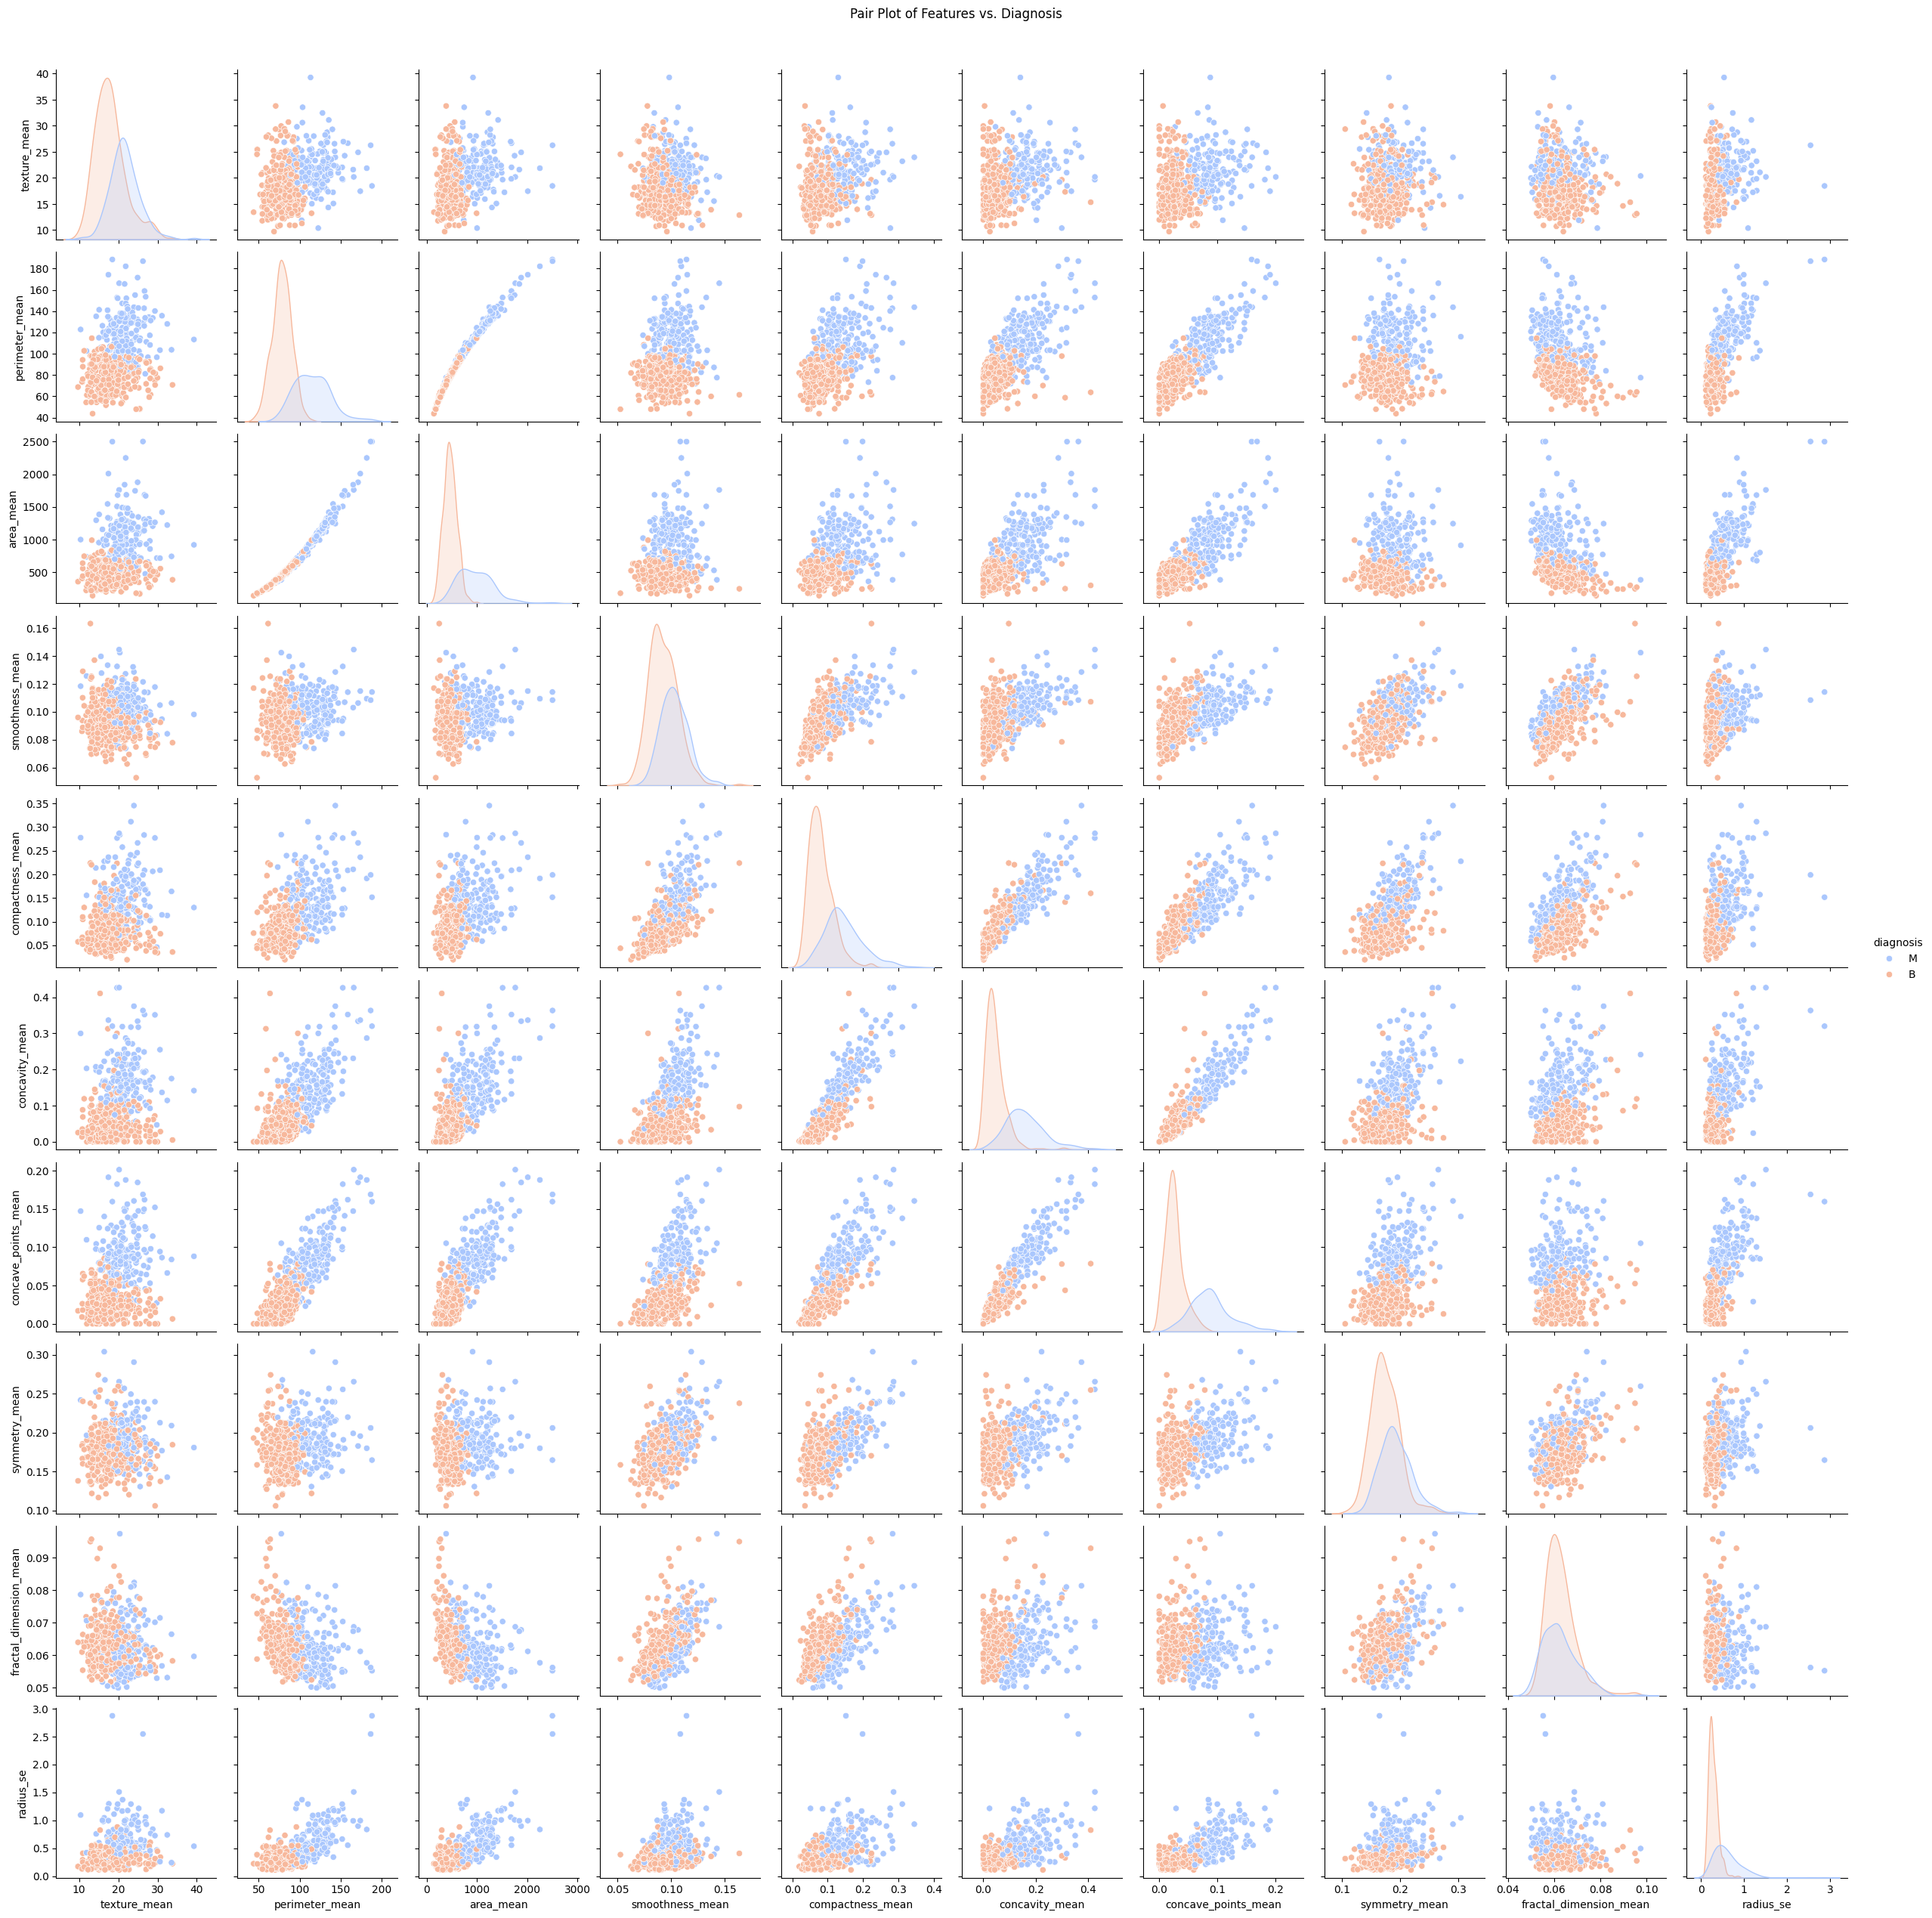

In [38]:
import seaborn as sns
import matplotlib.pyplot as plt

# Assuming 'data' is your DataFrame
# Create a pair plot
sns.pairplot(b_c_dataset, hue='diagnosis', palette='coolwarm', vars=b_c_dataset.columns[2:12])  # Adjust the range of columns as needed

# Add a title
plt.suptitle('Pair Plot of Features vs. Diagnosis', y=1.02)
plt.show()


In [39]:
# removing highly correlated features

corr_matrix = b_c_dataset.corr().abs() 

mask = np.triu(np.ones_like(corr_matrix, dtype = bool))
new_df = corr_matrix.mask(mask)

to_drop = [x for x in new_df.columns if any(new_df[x] > 0.92)]

b_c_dataset = b_c_dataset.drop(to_drop, axis = 1)

print(f"The reduced dataframe has {b_c_dataset.shape[1]} columns.")

ValueError: could not convert string to float: 'M'

In [139]:
b_c_dataset.columns

Index(['diagnosis', 'texture_mean', 'smoothness_mean', 'compactness_mean',
       'concave_points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'texture_se', 'area_se', 'smoothness_se', 'compactness_se',
       'concavity_se', 'concave_points_se', 'symmetry_se',
       'fractal_dimension_se', 'texture_worst', 'area_worst',
       'smoothness_worst', 'compactness_worst', 'concavity_worst',
       'concave_points_worst', 'symmetry_worst', 'fractal_dimension_worst'],
      dtype='object')

# #6. Feature Engineering
Feature engineering transforms raw data into a format suitable  for machine learning algorithms. It involves creating new features or modifying existing ones to enhance the performance of a machine learning model because effective feature engineering can significantly impact the success of a model, often leading to improved accuracy, robustness, and interpretability.

In [141]:
# Create a LabelEncoder instance
label_encoder = LabelEncoder()

# Encode the 'Diagnosis' column
b_c_dataset['diagnosis'] = label_encoder.fit_transform(b_c_dataset['diagnosis'])

# Verify the changes
print(b_c_dataset[['diagnosis']].head(10))

   diagnosis
0          1
1          1
2          1
3          1
4          1
5          1
6          1
7          1
8          1
9          1


In [142]:
# Check the distribution of the target variable
print(b_c_dataset['diagnosis'].value_counts())

diagnosis
0    357
1    212
Name: count, dtype: int64


In [143]:
X = b_c_dataset.drop(columns=[ 'diagnosis'])
y = b_c_dataset['diagnosis']

# Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [144]:
# over sampoling

In [145]:
from imblearn.over_sampling import SMOTE

# Initialize SMOTE
smote = SMOTE(random_state=42)

# Apply SMOTE to the training data
X_resampled, y_resampled = smote.fit_resample(X_scaled, y)

# Check the class distribution after oversampling
print(y_resampled.value_counts())


diagnosis
1    357
0    357
Name: count, dtype: int64


In [146]:
# Split the data
X_train, X_test, y_train, y_test = train_test_split(X_resampled, y_resampled, test_size=0.2, stratify=y_resampled, random_state=42)


In [147]:
X_train.shape

(571, 22)

In [148]:
from sklearn.linear_model import LogisticRegression

# Initialize the Logistic Regression model
lr_model = LogisticRegression(random_state=42, max_iter=1000)

# Train the model
lr_model.fit(X_train, y_train)

# Make predictions
y_pred_lr = lr_model.predict(X_test)


In [149]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Evaluate the Logistic Regression model
accuracy_lr = accuracy_score(y_test, y_pred_lr)
print(f'Logistic Regression Accuracy: {accuracy_lr:.2f}')
print(classification_report(y_test, y_pred_lr))
print(confusion_matrix(y_test, y_pred_lr))


Logistic Regression Accuracy: 0.98
              precision    recall  f1-score   support

           0       0.97      0.99      0.98        72
           1       0.99      0.97      0.98        71

    accuracy                           0.98       143
   macro avg       0.98      0.98      0.98       143
weighted avg       0.98      0.98      0.98       143

[[71  1]
 [ 2 69]]


In [150]:
from sklearn.ensemble import RandomForestClassifier

# Initialize the Random Forest model
rf_model = RandomForestClassifier(random_state=42)

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions
y_pred_rf = rf_model.predict(X_test)


In [151]:
# Evaluate the Random Forest model
accuracy_rf = accuracy_score(y_test, y_pred_rf)
print(f'Random Forest Accuracy: {accuracy_rf:.2f}')
print(classification_report(y_test, y_pred_rf))
print(confusion_matrix(y_test, y_pred_rf))


Random Forest Accuracy: 0.99
              precision    recall  f1-score   support

           0       0.97      1.00      0.99        72
           1       1.00      0.97      0.99        71

    accuracy                           0.99       143
   macro avg       0.99      0.99      0.99       143
weighted avg       0.99      0.99      0.99       143

[[72  0]
 [ 2 69]]


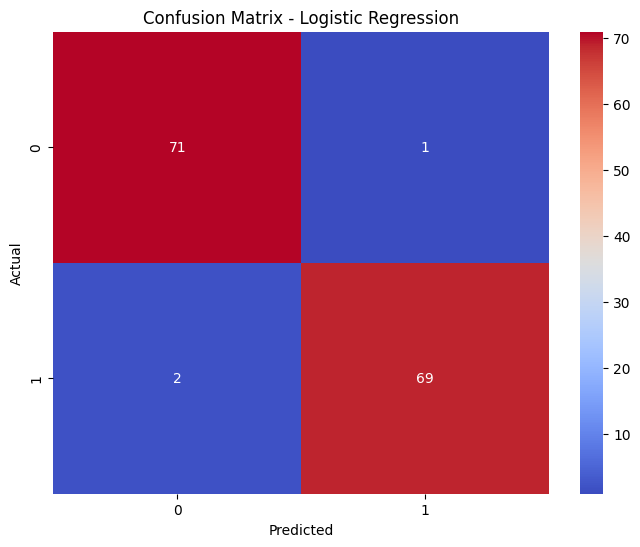

In [152]:
# Plot the confusion matrix for Logistic Regression
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, y_pred_lr), annot=True, cmap='coolwarm', fmt='d')
plt.title('Confusion Matrix - Logistic Regression')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()


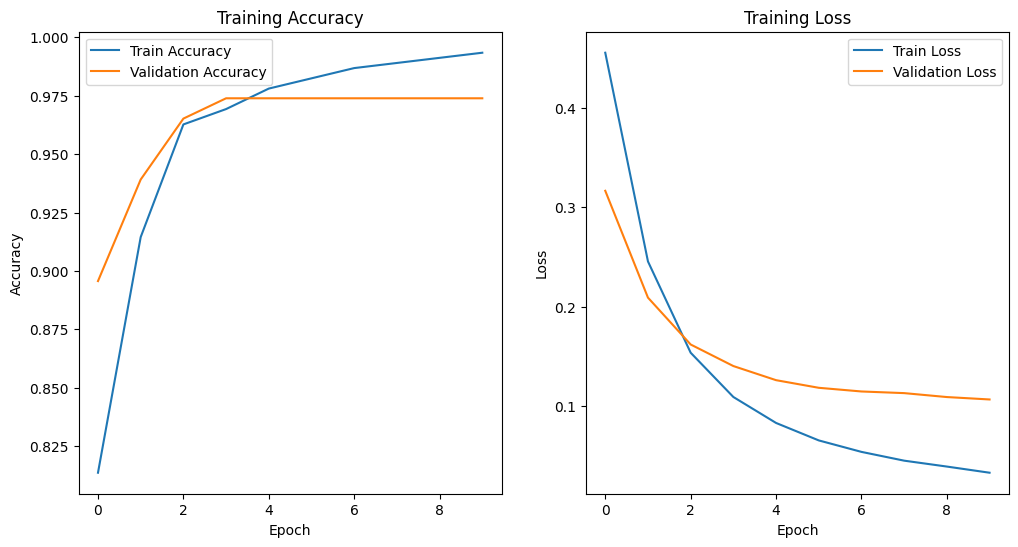

In [153]:
# Plot the training history
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()


In [154]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.utils import to_categorical

# Convert target variable to categorical
y_train_cat = to_categorical(y_train)
y_test_cat = to_categorical(y_test)

# Build the ANN model
model = Sequential()
model.add(Dense(32, input_dim=X_train.shape[1], activation='relu'))
model.add(Dense(16, activation='relu'))
model.add(Dense(2, activation='softmax'))

# Compile the model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Train the model
history = model.fit(X_train, y_train_cat, epochs=10, batch_size=10, validation_split=0.2)


Epoch 1/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5932 - loss: 1.0286 - val_accuracy: 0.8957 - val_loss: 0.4533
Epoch 2/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9023 - loss: 0.4207 - val_accuracy: 0.9130 - val_loss: 0.2598
Epoch 3/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9410 - loss: 0.2369 - val_accuracy: 0.9478 - val_loss: 0.1956
Epoch 4/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9621 - loss: 0.1431 - val_accuracy: 0.9478 - val_loss: 0.1697
Epoch 5/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9602 - loss: 0.1162 - val_accuracy: 0.9565 - val_loss: 0.1573
Epoch 6/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9705 - loss: 0.0875 - val_accuracy: 0.9565 - val_loss: 0.1514
Epoch 7/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9827 - loss: 0.0651 - val_accuracy: 0.9652 - val_loss: 0.1485
Epoch 8/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9914 - loss: 0.0541 - val_accuracy: 0.9652 - val_loss:

In [155]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Make predictions
y_pred_prob = model.predict(X_test)
y_pred = y_pred_prob.argmax(axis=1)

# Evaluate the ANN model
accuracy = accuracy_score(y_test, y_pred)
print(f'ANN Accuracy: {accuracy:.2f}')
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))


5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
ANN Accuracy: 0.97
              precision    recall  f1-score   support

           0       0.95      1.00      0.97        72
           1       1.00      0.94      0.97        71

    accuracy                           0.97       143
   macro avg       0.97      0.97      0.97       143
weighted avg       0.97      0.97      0.97       143

[[72  0]
 [ 4 67]]


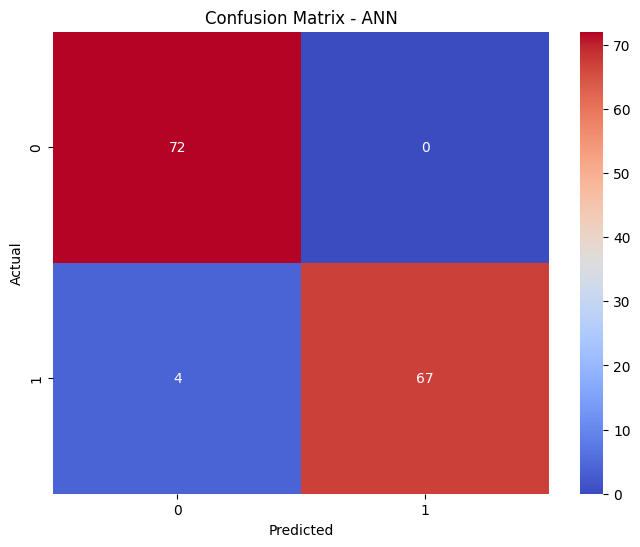

In [156]:
# Plot the confusion matrix for ANN
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, cmap='coolwarm', fmt='d')
plt.title('Confusion Matrix - ANN')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()


DT lgo~

In [157]:
from sklearn.tree import DecisionTreeClassifier

# Initialize the Decision Tree model
dt_model = DecisionTreeClassifier(random_state=42)

# Train the model
dt_model.fit(X_train, y_train)

# Make predictions
y_pred = dt_model.predict(X_test)


In [158]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Evaluate the Decision Tree model
accuracy = accuracy_score(y_test, y_pred)
print(f'Decision Tree Accuracy: {accuracy:.2f}')
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))


Decision Tree Accuracy: 0.94
              precision    recall  f1-score   support

           0       0.92      0.96      0.94        72
           1       0.96      0.92      0.94        71

    accuracy                           0.94       143
   macro avg       0.94      0.94      0.94       143
weighted avg       0.94      0.94      0.94       143

[[69  3]
 [ 6 65]]


# PCA


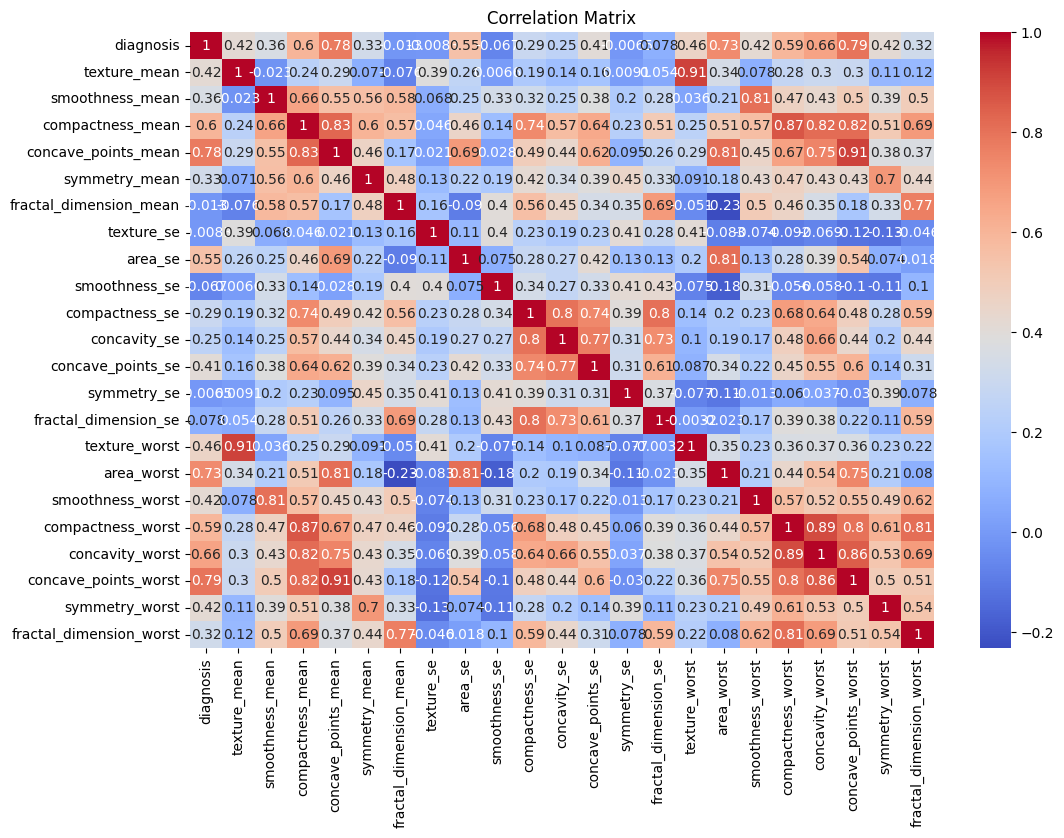

In [159]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Assuming 'data' is your DataFrame and 'Diagnosis' is your target variable
# Calculate the correlation matrix
corr_matrix = b_c_dataset.corr()

# Plot the correlation matrix
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()


TRy new


In [195]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Load the dataset
data = pd.read_csv('breast-cancer-wisconsin.csv')
from sklearn.preprocessing import LabelEncoder

# Create a LabelEncoder instance
label_encoder = LabelEncoder()

# Encode the 'Diagnosis' column
data['diagnosis'] = label_encoder.fit_transform(data['diagnosis'])
# Separate features and target
X = data.drop(columns=['id', 'diagnosis'])
y = data['diagnosis']

# Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


In [207]:
from sklearn.linear_model import LogisticRegression

# Initialize the Logistic Regression model
lr_model = LogisticRegression(random_state=42, max_iter=1000)

# Train the model
lr_model.fit(X_train, y_train)

# Make predictions
y_pred_lr = lr_model.predict(X_test)


In [199]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Evaluate the Logistic Regression model
accuracy_lr = accuracy_score(y_test, y_pred_lr)
print(f'Logistic Regression Accuracy: {accuracy_lr:.2f}')
print(classification_report(y_test, y_pred_lr))
print(confusion_matrix(y_test, y_pred_lr))


Logistic Regression Accuracy: 1.00
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        72
           1       1.00      1.00      1.00        42

    accuracy                           1.00       114
   macro avg       1.00      1.00      1.00       114
weighted avg       1.00      1.00      1.00       114

[[72  0]
 [ 0 42]]


In [90]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import pandas as pd
import numpy as np


In [91]:
from sklearn.feature_selection import SelectKBest, f_classif

# Initialize SelectKBest with ANOVA F-statistic to select top 10 features
selector = SelectKBest(score_func=f_classif, k=10)

# Fit selector on the full feature set
X_selected = selector.fit_transform(x, y)

# Get the top 10 feature names
selected_features = x.columns[selector.get_support()]

# Display the top 10 features
print("Top 10 Selected Features:")
print(selected_features)


Top 10 Selected Features:
Index(['Radius_Mean', 'Perimeter_Mean', 'Area_Mean', 'Concavity_Mean',
       'Concave_Points_Mean', 'Radius_Worst', 'Perimeter_Worst', 'Area_Worst',
       'Concavity_Worst', 'Concave_Points_Worst'],
      dtype='object')


In [92]:
# Filter the dataset to include only the selected top 10 features
X_top_10 = x[selected_features]

# Split the data into training and testing sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X_top_10, y, test_size=0.2, random_state=42)


Traning and validation loss

Traning and testing accuracy 


confusion matrix

In [160]:
import numpy as np

# Convert the resampled data back to a DataFrame
X_resampled_df = pd.DataFrame(X_resampled, columns=X.columns)

# Calculate the absolute correlation matrix
corr_matrix = X_resampled_df.corr().abs()

# Create a mask for the upper triangle of the correlation matrix
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

# Apply the mask to the correlation matrix
masked_corr_matrix = corr_matrix.mask(mask)

# Identify features to drop based on the correlation threshold
threshold = 0.95
to_drop = [c for c in masked_corr_matrix.columns if any(masked_corr_matrix[c] > threshold)]

# Drop the identified features
X_resampled_df = X_resampled_df.drop(columns=to_drop)

print(f"The reduced DataFrame has {X_resampled_df.shape[1]} columns.")


The reduced DataFrame has 22 columns.


In [161]:
# Split the data
X_train, X_test, y_train, y_test = train_test_split(X_resampled_df, y_resampled, test_size=0.2, stratify=y_resampled, random_state=42)


In [162]:
from sklearn.tree import DecisionTreeClassifier

# Initialize the Decision Tree model
dt_model = DecisionTreeClassifier(random_state=42)

# Train the model
dt_model.fit(X_train, y_train)

# Make predictions
y_pred = dt_model.predict(X_test)


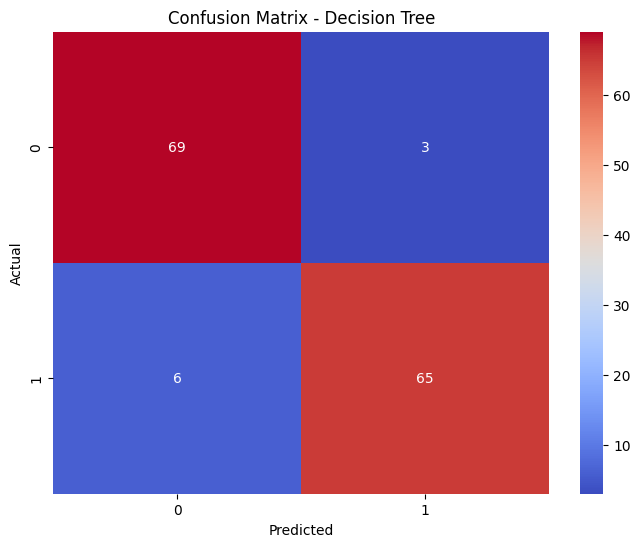

In [163]:
import seaborn as sns
import matplotlib.pyplot as plt

# Plot the confusion matrix for Decision Tree
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, cmap='coolwarm', fmt='d')
plt.title('Confusion Matrix - Decision Tree')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()


In [164]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Evaluate the Decision Tree model
accuracy = accuracy_score(y_test, y_pred)
print(f'Decision Tree Accuracy: {accuracy:.2f}')
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))


Decision Tree Accuracy: 0.94
              precision    recall  f1-score   support

           0       0.92      0.96      0.94        72
           1       0.96      0.92      0.94        71

    accuracy                           0.94       143
   macro avg       0.94      0.94      0.94       143
weighted avg       0.94      0.94      0.94       143

[[69  3]
 [ 6 65]]


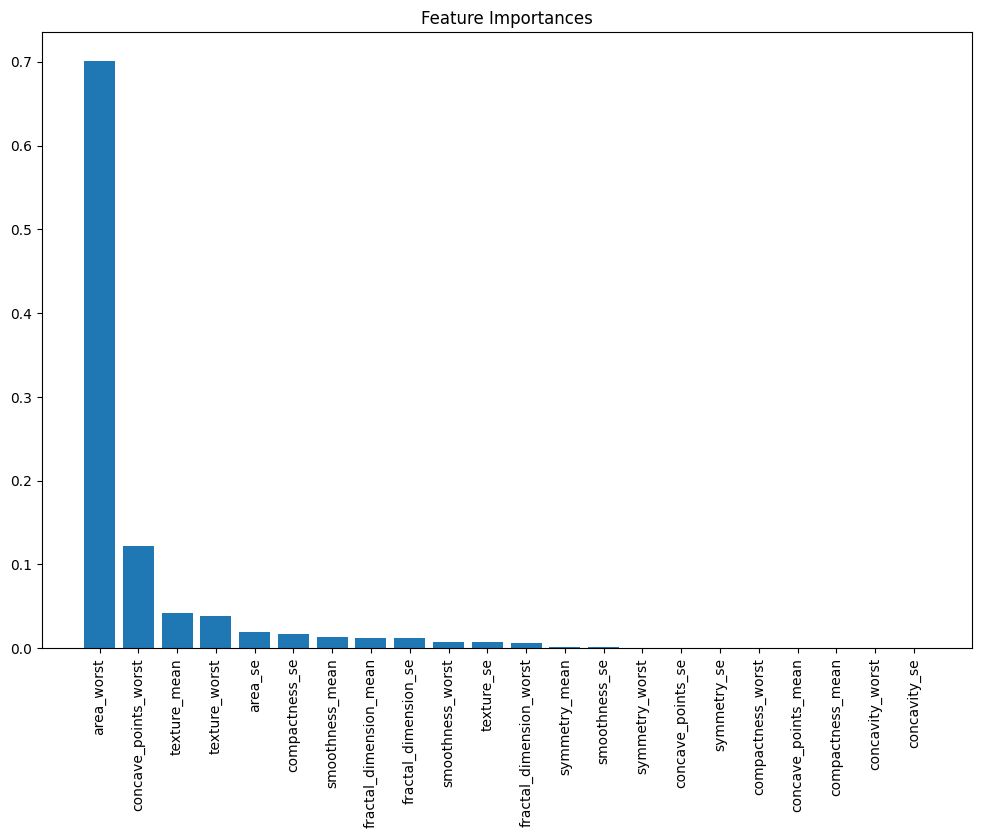

In [99]:
import numpy as np

# Get feature importances
importances = dt_model.feature_importances_
indices = np.argsort(importances)[::-1]

# Plot the feature importances
plt.figure(figsize=(12, 8))
plt.title('Feature Importances')
plt.bar(range(X_train.shape[1]), importances[indices], align='center')
plt.xticks(range(X_train.shape[1]), X_train.columns[indices], rotation=90)
plt.show()


In [173]:
X_train, X_test, y_train, y_test = train_test_split(X_resampled, y_resampled, test_size=0.2, stratify=y_resampled, random_state=42)


In [174]:
from sklearn.linear_model import LogisticRegression

# Initialize the Logistic Regression model
lr_model = LogisticRegression(random_state=42, max_iter=1000)

# Train the model
lr_model.fit(X_train, y_train)

# Make predictions
y_pred_lr = lr_model.predict(X_test)
y_pred_lr_prob = lr_model.predict_proba(X_test)[:, 1]


In [175]:
from sklearn.tree import DecisionTreeClassifier

# Initialize the Decision Tree model
dt_model = DecisionTreeClassifier(random_state=42)

# Train the model
dt_model.fit(X_train, y_train)

# Make predictions
y_pred_dt = dt_model.predict(X_test)
y_pred_dt_prob = dt_model.predict_proba(X_test)[:, 1]


In [176]:
from sklearn.ensemble import RandomForestClassifier

# Initialize the Random Forest model
rf_model = RandomForestClassifier(random_state=42)

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions
y_pred_rf = rf_model.predict(X_test)
y_pred_rf_prob = rf_model.predict_proba(X_test)[:, 1]


In [177]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.utils import to_categorical

# Convert target variable to categorical
y_train_cat = to_categorical(y_train)
y_test_cat = to_categorical(y_test)

# Build the ANN model
ann_model = Sequential()
ann_model.add(Dense(32, input_dim=X_train.shape[1], activation='relu'))
ann_model.add(Dense(16, activation='relu'))
ann_model.add(Dense(2, activation='softmax'))

# Compile the model
ann_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Train the model
ann_model.fit(X_train, y_train_cat, epochs=50, batch_size=10, validation_split=0.2, verbose=0)

# Make predictions
y_pred_ann_prob = ann_model.predict(X_test)[:, 1]
y_pred_ann = (y_pred_ann_prob > 0.5).astype(int)


5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 


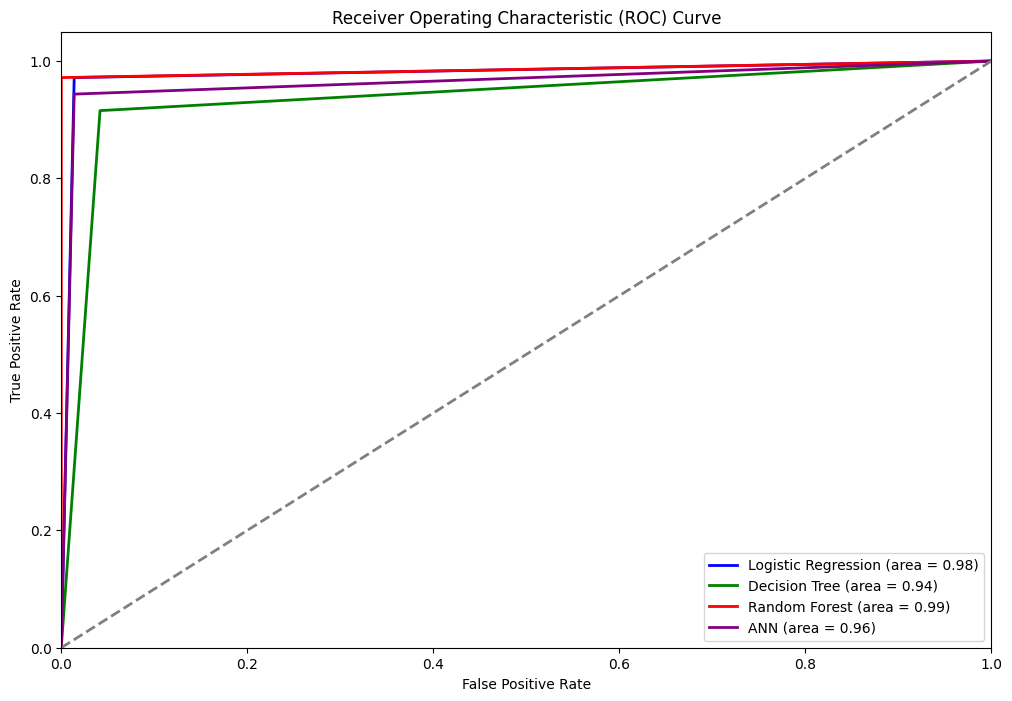

In [178]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Compute ROC curve and ROC area for each model
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_pred_lr)
roc_auc_lr = auc(fpr_lr, tpr_lr)

fpr_dt, tpr_dt, _ = roc_curve(y_test, y_pred_dt)
roc_auc_dt = auc(fpr_dt, tpr_dt)

fpr_rf, tpr_rf, _ = roc_curve(y_test, y_pred_rf)
roc_auc_rf = auc(fpr_rf, tpr_rf)

fpr_ann, tpr_ann, _ = roc_curve(y_test, y_pred_ann)
roc_auc_ann = auc(fpr_ann, tpr_ann)

# Plot ROC curves
plt.figure(figsize=(12, 8))
plt.plot(fpr_lr, tpr_lr, color='blue', lw=2, label='Logistic Regression (area = %0.2f)' % roc_auc_lr)
plt.plot(fpr_dt, tpr_dt, color='green', lw=2, label='Decision Tree (area = %0.2f)' % roc_auc_dt)
plt.plot(fpr_rf, tpr_rf, color='red', lw=2, label='Random Forest (area = %0.2f)' % roc_auc_rf)
plt.plot(fpr_ann, tpr_ann, color='purple', lw=2, label='ANN (area = %0.2f)' % roc_auc_ann)
plt.plot([0, 1], [0, 1], color='grey', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()


In [179]:
# Calculate accuracy for each model
accuracy_lr = accuracy_score(y_test, y_pred_lr)
accuracy_dt = accuracy_score(y_test, y_pred_dt)
accuracy_rf = accuracy_score(y_test, y_pred_rf)
accuracy_ann = accuracy_score(y_test, y_pred_ann)

# Create a DataFrame to display the accuracy table
accuracy_table = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree', 'Random Forest', 'ANN'],
    'Accuracy': [accuracy_lr, accuracy_dt, accuracy_rf, accuracy_ann]
})

print(accuracy_table)


                 Model  Accuracy
0  Logistic Regression  0.979021
1        Decision Tree  0.937063
2        Random Forest  0.986014
3                  ANN  0.965035
